AE/DAE/SAE Latent Temporal Sequences + LSTM/Transformer Forecasting

Import libraries

In [ ]:
import os
import shutil
from google.colab import drive

# Remove any local directory created prior to mounting
if os.path.exists('/content/drive'):
    try:
        shutil.rmtree('/content/drive')
    except Exception as e:
        print(f"Warning: Could not clear local mountpoint: {e}")

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
import os
import json
import joblib
import random
import warnings
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf

from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    LSTM,
    Dropout,
    BatchNormalization,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D,
    Add
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

warnings.filterwarnings("ignore")

SEED = 42
HORIZON = 28
SEQUENCE_LENGTH = 28

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Step 12 libraries loaded.")

TensorFlow: 2.20.0
Step 12 libraries loaded.


Define paths

In [ ]:
PROJECT_DIR = "/content/drive/MyDrive/GC210_Retail_Forecasting"

RAW_DIR = os.path.join(PROJECT_DIR, "data", "raw")
PROCESSED_DIR = os.path.join(PROJECT_DIR, "data", "processed")
SUPERVISED_DIR = os.path.join(PROCESSED_DIR, "supervised")

LATENT_SEQUENCE_DIR = os.path.join(
    PROCESSED_DIR,
    "latent_sequences"
)

MODEL_DIR = os.path.join(PROJECT_DIR, "models")

AE_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "autoencoder"
)

DAE_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "denoising_autoencoder"
)

SAE_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "stacked_autoencoder"
)

LATENT_TEMPORAL_MODEL_DIR = os.path.join(
    MODEL_DIR,
    "latent_temporal"
)

RESULTS_DIR = os.path.join(PROJECT_DIR, "results")
METRICS_DIR = os.path.join(RESULTS_DIR, "metrics")
PREDICTIONS_DIR = os.path.join(RESULTS_DIR, "predictions")
FIGURES_DIR = os.path.join(RESULTS_DIR, "figures")

for folder in [
    LATENT_SEQUENCE_DIR,
    LATENT_TEMPORAL_MODEL_DIR,
    METRICS_DIR,
    PREDICTIONS_DIR,
    FIGURES_DIR
]:
    os.makedirs(folder, exist_ok=True)

print("Step 12 directories ready.")

Step 12 directories ready.


Locate encoder models robustly

In [ ]:
def first_existing(paths):
    for path in paths:
        if os.path.exists(path):
            return path
    return None


AE_ENCODER_PATH = first_existing([
    os.path.join(AE_MODEL_DIR, "ae_encoder.keras"),
    os.path.join(MODEL_DIR, "ae_encoder.keras"),
    os.path.join(MODEL_DIR, "autoencoder_encoder.keras"),
])

DAE_ENCODER_PATH = first_existing([
    os.path.join(DAE_MODEL_DIR, "dae_encoder.keras"),
    os.path.join(MODEL_DIR, "dae_encoder.keras"),
    os.path.join(MODEL_DIR, "denoising_autoencoder_encoder.keras"),
])

SAE_ENCODER_PATH = first_existing([
    os.path.join(SAE_MODEL_DIR, "sae_encoder.keras"),
    os.path.join(MODEL_DIR, "sae_encoder.keras"),
])

print("AE encoder :", AE_ENCODER_PATH)
print("DAE encoder:", DAE_ENCODER_PATH)
print("SAE encoder:", SAE_ENCODER_PATH)

missing = []

if AE_ENCODER_PATH is None:
    missing.append("AE encoder")

if DAE_ENCODER_PATH is None:
    missing.append("DAE encoder")

if SAE_ENCODER_PATH is None:
    missing.append("SAE encoder")

if missing:
    raise FileNotFoundError(
        "Missing encoder models: " + ", ".join(missing)
    )

print("\nAll three encoders found.")

AE encoder : /content/drive/MyDrive/GC210_Retail_Forecasting/models/autoencoder/ae_encoder.keras
DAE encoder: /content/drive/MyDrive/GC210_Retail_Forecasting/models/denoising_autoencoder/dae_encoder.keras
SAE encoder: /content/drive/MyDrive/GC210_Retail_Forecasting/models/stacked_autoencoder/sae_encoder.keras

All three encoders found.


Load supervised configuration and datasets

In [ ]:
CONFIG_PATH = os.path.join(
    SUPERVISED_DIR,
    "supervised_config.json"
)

TRAIN_PATH = os.path.join(
    SUPERVISED_DIR,
    "train_supervised_28d.parquet"
)

VAL_PATH = os.path.join(
    SUPERVISED_DIR,
    "validation_supervised_28d.parquet"
)

TEST_PATH = os.path.join(
    SUPERVISED_DIR,
    "test_supervised_28d.parquet"
)

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

FEATURES = config["features"]
TARGETS = config["targets"]

train_supervised = pd.read_parquet(TRAIN_PATH)
val_supervised = pd.read_parquet(VAL_PATH)
test_supervised = pd.read_parquet(TEST_PATH)

for df in [
    train_supervised,
    val_supervised,
    test_supervised
]:
    df["date"] = pd.to_datetime(df["date"])

print("Number of features:", len(FEATURES))
print("Targets:", len(TARGETS))

print("Train:", train_supervised.shape)
print("Validation:", val_supervised.shape)
print("Test:", test_supervised.shape)

Number of features: 40
Targets: 28
Train: (79200, 71)
Validation: (300, 71)
Test: (300, 71)


Load raw M5 data

In [ ]:
SALES_PATH = os.path.join(
    RAW_DIR,
    "sales_train_evaluation.csv"
)

CALENDAR_PATH = os.path.join(
    RAW_DIR,
    "calendar.csv"
)

PRICES_PATH = os.path.join(
    RAW_DIR,
    "sell_prices.csv"
)

sales_wide = pd.read_csv(SALES_PATH)
calendar = pd.read_csv(CALENDAR_PATH)
prices = pd.read_csv(PRICES_PATH)

print("Sales   :", sales_wide.shape)
print("Calendar:", calendar.shape)
print("Prices  :", prices.shape)

Sales   : (30490, 1947)
Calendar: (1969, 14)
Prices  : (6841121, 4)


Normalize IDs and select the same 300 series

In [ ]:
def normalize_m5_id(x):
    return (
        str(x)
        .replace("_validation", "")
        .replace("_evaluation", "")
    )


sales_wide["series_key"] = (
    sales_wide["id"]
    .apply(normalize_m5_id)
)

selected_series = set(
    pd.concat([
        train_supervised["series_key"],
        val_supervised["series_key"],
        test_supervised["series_key"]
    ])
    .astype(str)
    .unique()
)

sales_selected = sales_wide[
    sales_wide["series_key"].isin(
        selected_series
    )
].copy()

print("Requested series:", len(selected_series))
print(
    "Matched series:",
    sales_selected["series_key"].nunique()
)

if (
    sales_selected["series_key"].nunique()
    != len(selected_series)
):
    raise ValueError(
        "Some selected M5 series were not found."
    )

Requested series: 300
Matched series: 300


Convert sales to daily long format

In [ ]:
META_COLS = [
    "id",
    "item_id",
    "dept_id",
    "cat_id",
    "store_id",
    "state_id",
    "series_key"
]

DAY_COLS = [
    col
    for col in sales_selected.columns
    if col.startswith("d_")
]

daily_df = sales_selected[
    META_COLS + DAY_COLS
].melt(
    id_vars=META_COLS,
    value_vars=DAY_COLS,
    var_name="d",
    value_name="sales"
)

daily_df["sales"] = pd.to_numeric(
    daily_df["sales"],
    errors="coerce"
)

print("Daily long data:", daily_df.shape)

display(daily_df.head())

Daily long data: (582300, 9)


,id,item_id,dept_id,cat_id,store_id,state_id,series_key,d,sales
0,HOBBIES_1_100_CA_1_evaluation,HOBBIES_1_100,HOBBIES_1,HOBBIES,CA_1,CA,HOBBIES_1_100_CA_1,d_1,1
1,HOBBIES_1_287_CA_1_evaluation,HOBBIES_1_287,HOBBIES_1,HOBBIES,CA_1,CA,HOBBIES_1_287_CA_1,d_1,0
2,HOBBIES_2_008_CA_1_evaluation,HOBBIES_2_008,HOBBIES_2,HOBBIES,CA_1,CA,HOBBIES_2_008_CA_1,d_1,0
3,HOBBIES_2_076_CA_1_evaluation,HOBBIES_2_076,HOBBIES_2,HOBBIES,CA_1,CA,HOBBIES_2_076_CA_1,d_1,0
4,HOUSEHOLD_1_176_CA_1_evaluation,HOUSEHOLD_1_176,HOUSEHOLD_1,HOUSEHOLD,CA_1,CA,HOUSEHOLD_1_176_CA_1,d_1,0


Prepare calendar features

In [ ]:
calendar["date"] = pd.to_datetime(
    calendar["date"]
)

calendar["day_of_week"] = (
    calendar["date"].dt.dayofweek
)

calendar["day_of_month"] = (
    calendar["date"].dt.day
)

calendar["week_of_year"] = (
    calendar["date"]
    .dt.isocalendar()
    .week
    .astype(int)
)

calendar["month"] = (
    calendar["date"].dt.month
)

calendar["quarter"] = (
    calendar["date"].dt.quarter
)

calendar["year"] = (
    calendar["date"].dt.year
)

calendar["is_weekend"] = (
    calendar["day_of_week"] >= 5
).astype(int)

print("Calendar features prepared.")

Calendar features prepared.


Prepare event and SNAP variables

In [ ]:
for col in [
    "event_name_1",
    "event_type_1",
    "event_name_2",
    "event_type_2"
]:
    if col in calendar.columns:
        calendar[col] = (
            calendar[col]
            .fillna("None")
        )

calendar["has_event_1"] = (
    calendar["event_name_1"] != "None"
).astype(int)

calendar["has_event_2"] = (
    calendar["event_name_2"] != "None"
).astype(int)

calendar["has_event"] = (
    (
        calendar["has_event_1"] == 1
    )
    |
    (
        calendar["has_event_2"] == 1
    )
).astype(int)

calendar["snap_any"] = (
    calendar[
        ["snap_CA", "snap_TX", "snap_WI"]
    ]
    .max(axis=1)
    .astype(int)
)

print("Event/SNAP variables prepared.")

Event/SNAP variables prepared.


Merge calendar with daily sales

In [ ]:
calendar_columns = [
    "d",
    "date",
    "wm_yr_wk",
    "day_of_week",
    "day_of_month",
    "week_of_year",
    "month",
    "quarter",
    "year",
    "is_weekend",
    "has_event_1",
    "has_event_2",
    "has_event",
    "snap_CA",
    "snap_TX",
    "snap_WI",
    "snap_any"
]

daily_df = daily_df.merge(
    calendar[calendar_columns],
    on="d",
    how="left"
)

print(
    "After calendar merge:",
    daily_df.shape
)

After calendar merge: (582300, 25)


Merge prices

In [ ]:
daily_df = daily_df.merge(
    prices,
    on=[
        "store_id",
        "item_id",
        "wm_yr_wk"
    ],
    how="left"
)

daily_df = (
    daily_df
    .sort_values([
        "series_key",
        "date"
    ])
    .reset_index(drop=True)
)

print(
    "After price merge:",
    daily_df.shape
)

After price merge: (582300, 26)


Create leakage-safe lag features

In [ ]:
grouped_sales = daily_df.groupby(
    "series_key"
)["sales"]

for lag in [
    1,
    7,
    14,
    28
]:
    daily_df[
        f"lag_{lag}"
    ] = grouped_sales.shift(lag)

print("Lag features created.")

Lag features created.


Create rolling demand features

In [ ]:
daily_df["rolling_mean_7"] = (
    daily_df.groupby(
        "series_key"
    )["sales"]
    .transform(
        lambda s:
        s.shift(1)
        .rolling(7)
        .mean()
    )
)

daily_df["rolling_mean_14"] = (
    daily_df.groupby(
        "series_key"
    )["sales"]
    .transform(
        lambda s:
        s.shift(1)
        .rolling(14)
        .mean()
    )
)

daily_df["rolling_mean_28"] = (
    daily_df.groupby(
        "series_key"
    )["sales"]
    .transform(
        lambda s:
        s.shift(1)
        .rolling(28)
        .mean()
    )
)

daily_df["rolling_std_7"] = (
    daily_df.groupby(
        "series_key"
    )["sales"]
    .transform(
        lambda s:
        s.shift(1)
        .rolling(7)
        .std()
    )
)

daily_df["rolling_std_28"] = (
    daily_df.groupby(
        "series_key"
    )["sales"]
    .transform(
        lambda s:
        s.shift(1)
        .rolling(28)
        .std()
    )
)

print("Rolling features created.")

Rolling features created.


Demand-change features

In [ ]:
EPS = 1e-6

daily_df["demand_ratio_7_28"] = (
    daily_df["rolling_mean_7"]
    /
    (
        daily_df["rolling_mean_28"]
        + EPS
    )
)

daily_df["demand_change_7"] = (
    daily_df["lag_1"]
    -
    daily_df["lag_7"]
)

print("Demand-change features created.")

Demand-change features created.


Price features

In [ ]:
daily_df["price_change"] = (
    daily_df.groupby(
        "series_key"
    )["sell_price"]
    .diff()
)

previous_price = (
    daily_df.groupby(
        "series_key"
    )["sell_price"]
    .shift(1)
)

daily_df["price_change_pct"] = (
    daily_df["price_change"]
    /
    (
        previous_price
        + EPS
    )
)

daily_df["price_volatility_7"] = (
    daily_df.groupby(
        "series_key"
    )["sell_price"]
    .transform(
        lambda s:
        s.shift(1)
        .rolling(7)
        .std()
    )
)

print("Price features created.")

Price features created.


Cyclical temporal features

In [ ]:
daily_df["dow_sin"] = np.sin(
    2 * np.pi *
    daily_df["day_of_week"] / 7
)

daily_df["dow_cos"] = np.cos(
    2 * np.pi *
    daily_df["day_of_week"] / 7
)

daily_df["month_sin"] = np.sin(
    2 * np.pi *
    daily_df["month"] / 12
)

daily_df["month_cos"] = np.cos(
    2 * np.pi *
    daily_df["month"] / 12
)

daily_df["week_sin"] = np.sin(
    2 * np.pi *
    daily_df["week_of_year"] / 52
)

daily_df["week_cos"] = np.cos(
    2 * np.pi *
    daily_df["week_of_year"] / 52
)

print("Cyclical features created.")

Cyclical features created.


Reproduce categorical codes safel

In [ ]:
categorical_pairs = {
    "item_id": "item_id_code",
    "dept_id": "dept_id_code",
    "cat_id": "cat_id_code",
    "store_id": "store_id_code",
    "state_id": "state_id_code"
}

reference_df = pd.concat(
    [
        train_supervised,
        val_supervised,
        test_supervised
    ],
    ignore_index=True
)

for raw_col, code_col in categorical_pairs.items():

    if (
        raw_col in reference_df.columns
        and
        code_col in reference_df.columns
    ):

        mapping = (
            reference_df[
                [raw_col, code_col]
            ]
            .drop_duplicates()
            .dropna()
            .set_index(raw_col)[code_col]
            .to_dict()
        )

        daily_df[code_col] = (
            daily_df[raw_col]
            .map(mapping)
        )

        print(
            code_col,
            "mapped from supervised data."
        )

    else:

        print(
            "Fallback encoding for:",
            code_col
        )

        categories = sorted(
            daily_df[raw_col]
            .astype(str)
            .unique()
        )

        mapping = {
            value: idx
            for idx, value
            in enumerate(categories)
        }

        daily_df[code_col] = (
            daily_df[raw_col]
            .astype(str)
            .map(mapping)
        )

Fallback encoding for: item_id_code
Fallback encoding for: dept_id_code
Fallback encoding for: cat_id_code
Fallback encoding for: store_id_code
Fallback encoding for: state_id_code


Verify all 41 features

In [ ]:
missing_features = [
    feature
    for feature in FEATURES
    if feature not in daily_df.columns
]

print(
    "Expected features:",
    len(FEATURES)
)

print(
    "Available features:",
    sum(
        feature in daily_df.columns
        for feature in FEATURES
    )
)

if missing_features:

    print(
        "Missing:",
        missing_features
    )

    raise ValueError(
        "Daily feature reconstruction does "
        "not match Step 5."
    )

print(
    "All 41 features are available."
)

Expected features: 40
Available features: 40
All 41 features are available.


Convert features to numeric

In [ ]:
for feature in FEATURES:

    daily_df[feature] = pd.to_numeric(
        daily_df[feature],
        errors="coerce"
    )

daily_df[FEATURES] = (
    daily_df[FEATURES]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
)

print(
    "Initial feature NaNs:",
    daily_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

Initial feature NaNs: 607016


Fill missing values using training medians

In [ ]:
train_feature_medians = (
    train_supervised[
        FEATURES
    ]
    .apply(
        pd.to_numeric,
        errors="coerce"
    )
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .median()
    .fillna(0)
)

daily_df[FEATURES] = (
    daily_df[FEATURES]
    .fillna(
        train_feature_medians
    )
)

print(
    "Remaining NaNs:",
    daily_df[FEATURES]
    .isna()
    .sum()
    .sum()
)

Remaining NaNs: 0


Load the original neural scaler

In [ ]:
SCALER_PATH = os.path.join(
    MODEL_DIR,
    "neural_feature_scaler.pkl"
)

if not os.path.exists(
    SCALER_PATH
):
    raise FileNotFoundError(
        "neural_feature_scaler.pkl missing."
    )

feature_scaler = joblib.load(
    SCALER_PATH
)

X_daily = daily_df[
    FEATURES
].to_numpy(
    dtype=np.float32
)

X_daily_scaled = (
    feature_scaler
    .transform(X_daily)
    .astype(np.float32)
)

print(
    "Daily scaled features:",
    X_daily_scaled.shape
)

print(
    "Finite:",
    np.isfinite(
        X_daily_scaled
    ).all()
)

Daily scaled features: (582300, 40)
Finite: True


Load AE, DAE and SAE encoders

In [ ]:
ae_encoder = tf.keras.models.load_model(
    AE_ENCODER_PATH,
    compile=False
)

dae_encoder = tf.keras.models.load_model(
    DAE_ENCODER_PATH,
    compile=False
)

sae_encoder = tf.keras.models.load_model(
    SAE_ENCODER_PATH,
    compile=False
)

print(
    "AE output :",
    ae_encoder.output_shape
)

print(
    "DAE output:",
    dae_encoder.output_shape
)

print(
    "SAE output:",
    sae_encoder.output_shape
)

AE output : (None, 8)
DAE output: (None, 8)
SAE output: (None, 8)


Validate encoder input dimensions

In [ ]:
for name, encoder in [
    ("AE", ae_encoder),
    ("DAE", dae_encoder),
    ("SAE", sae_encoder)
]:

    encoder_input_dim = (
        encoder.input_shape[-1]
    )

    print(
        name,
        "input dimension:",
        encoder_input_dim
    )

    if encoder_input_dim != len(FEATURES):

        raise ValueError(
            f"{name} expects "
            f"{encoder_input_dim} features, "
            f"but daily data has "
            f"{len(FEATURES)}."
        )

print(
    "Encoder dimensions verified."
)

AE input dimension: 40
DAE input dimension: 40
SAE input dimension: 40
Encoder dimensions verified.


Generate daily AE latent representations

In [ ]:
Z_daily_ae = ae_encoder.predict(
    X_daily_scaled,
    batch_size=1024,
    verbose=1
)

Z_daily_ae = np.asarray(
    Z_daily_ae,
    dtype=np.float32
)

print(
    "AE latent:",
    Z_daily_ae.shape
)

569/569 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
AE latent: (582300, 8)


Generate daily DAE latent representations

In [ ]:
Z_daily_dae = dae_encoder.predict(
    X_daily_scaled,
    batch_size=1024,
    verbose=1
)

Z_daily_dae = np.asarray(
    Z_daily_dae,
    dtype=np.float32
)

print(
    "DAE latent:",
    Z_daily_dae.shape
)

569/569 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
DAE latent: (582300, 8)


Generate daily SAE latent representations

In [ ]:
Z_daily_sae = sae_encoder.predict(
    X_daily_scaled,
    batch_size=1024,
    verbose=1
)

Z_daily_sae = np.asarray(
    Z_daily_sae,
    dtype=np.float32
)

print(
    "SAE latent:",
    Z_daily_sae.shape
)

569/569 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
SAE latent: (582300, 8)


Verify latent dimensions

In [ ]:
LATENT_DIM_AE = Z_daily_ae.shape[1]
LATENT_DIM_DAE = Z_daily_dae.shape[1]
LATENT_DIM_SAE = Z_daily_sae.shape[1]

print(
    "AE latent dimension :",
    LATENT_DIM_AE
)

print(
    "DAE latent dimension:",
    LATENT_DIM_DAE
)

print(
    "SAE latent dimension:",
    LATENT_DIM_SAE
)

if not (
    LATENT_DIM_AE
    ==
    LATENT_DIM_DAE
    ==
    LATENT_DIM_SAE
):

    raise ValueError(
        "AE/DAE/SAE latent dimensions differ."
    )

LATENT_DIM = LATENT_DIM_AE

print(
    "\nFinal latent dimension:",
    LATENT_DIM
)

AE latent dimension : 8
DAE latent dimension: 8
SAE latent dimension: 8

Final latent dimension: 8


Attach latent vectors to daily data

In [ ]:
for i in range(LATENT_DIM):

    daily_df[
        f"AE_Z{i+1}"
    ] = Z_daily_ae[:, i]

    daily_df[
        f"DAE_Z{i+1}"
    ] = Z_daily_dae[:, i]

    daily_df[
        f"SAE_Z{i+1}"
    ] = Z_daily_sae[:, i]

print(
    "Daily latent representations attached."
)

Daily latent representations attached.


Build fast latent lookup

In [ ]:
daily_df = (
    daily_df
    .sort_values([
        "series_key",
        "date"
    ])
    .reset_index(drop=True)
)

AE_COLS = [
    f"AE_Z{i+1}"
    for i in range(LATENT_DIM)
]

DAE_COLS = [
    f"DAE_Z{i+1}"
    for i in range(LATENT_DIM)
]

SAE_COLS = [
    f"SAE_Z{i+1}"
    for i in range(LATENT_DIM)
]

latent_lookup = {}

for series_key, group in daily_df.groupby(
    "series_key"
):

    group = (
        group
        .sort_values("date")
        .set_index("date")
    )

    latent_lookup[
        str(series_key)
    ] = {
        "AE":
            group[AE_COLS],

        "DAE":
            group[DAE_COLS],

        "SAE":
            group[SAE_COLS]
    }

print(
    "Latent lookup series:",
    len(latent_lookup)
)

Latent lookup series: 300


Define latent sequence constructor

In [ ]:
def build_latent_sequences(
    supervised_df,
    representation,
    latent_columns
):

    X = []
    y = []
    metadata = []

    skipped = 0

    for _, row in supervised_df.iterrows():

        series_key = str(
            row["series_key"]
        )

        origin_date = pd.Timestamp(
            row["date"]
        )

        if series_key not in latent_lookup:
            skipped += 1
            continue

        latent_table = (
            latent_lookup[
                series_key
            ][representation]
        )

        start_date = (
            origin_date
            -
            pd.Timedelta(
                days=SEQUENCE_LENGTH - 1
            )
        )

        required_dates = pd.date_range(
            start=start_date,
            end=origin_date,
            freq="D"
        )

        try:

            sequence = (
                latent_table
                .loc[
                    required_dates,
                    latent_columns
                ]
                .to_numpy(
                    dtype=np.float32
                )
            )

        except KeyError:

            skipped += 1
            continue

        target = (
            row[TARGETS]
            .to_numpy(
                dtype=np.float32
            )
        )

        if sequence.shape != (
            SEQUENCE_LENGTH,
            len(latent_columns)
        ):
            skipped += 1
            continue

        if not np.isfinite(
            sequence
        ).all():
            skipped += 1
            continue

        if not np.isfinite(
            target
        ).all():
            skipped += 1
            continue

        X.append(sequence)
        y.append(target)

        metadata.append({
            "series_key":
                series_key,

            "origin_date":
                origin_date
        })

    X = np.asarray(
        X,
        dtype=np.float32
    )

    y = np.asarray(
        y,
        dtype=np.float32
    )

    metadata = pd.DataFrame(
        metadata
    )

    print(
        representation,
        "sequences:",
        X.shape,
        "targets:",
        y.shape,
        "skipped:",
        skipped
    )

    return X, y, metadata

Build AE temporal sequences

In [ ]:
X_train_ae, y_train_ae, meta_train_ae = (
    build_latent_sequences(
        train_supervised,
        "AE",
        AE_COLS
    )
)

X_val_ae, y_val_ae, meta_val_ae = (
    build_latent_sequences(
        val_supervised,
        "AE",
        AE_COLS
    )
)

X_test_ae, y_test_ae, meta_test_ae = (
    build_latent_sequences(
        test_supervised,
        "AE",
        AE_COLS
    )
)

AE sequences: (79200, 28, 8) targets: (79200, 28) skipped: 0
AE sequences: (300, 28, 8) targets: (300, 28) skipped: 0
AE sequences: (300, 28, 8) targets: (300, 28) skipped: 0


Build DAE temporal sequences

In [ ]:
X_train_dae, y_train_dae, meta_train_dae = (
    build_latent_sequences(
        train_supervised,
        "DAE",
        DAE_COLS
    )
)

X_val_dae, y_val_dae, meta_val_dae = (
    build_latent_sequences(
        val_supervised,
        "DAE",
        DAE_COLS
    )
)

X_test_dae, y_test_dae, meta_test_dae = (
    build_latent_sequences(
        test_supervised,
        "DAE",
        DAE_COLS
    )
)

DAE sequences: (79200, 28, 8) targets: (79200, 28) skipped: 0
DAE sequences: (300, 28, 8) targets: (300, 28) skipped: 0
DAE sequences: (300, 28, 8) targets: (300, 28) skipped: 0


Build SAE temporal sequences

In [ ]:
X_train_sae, y_train_sae, meta_train_sae = (
    build_latent_sequences(
        train_supervised,
        "SAE",
        SAE_COLS
    )
)

X_val_sae, y_val_sae, meta_val_sae = (
    build_latent_sequences(
        val_supervised,
        "SAE",
        SAE_COLS
    )
)

X_test_sae, y_test_sae, meta_test_sae = (
    build_latent_sequences(
        test_supervised,
        "SAE",
        SAE_COLS
    )
)

SAE sequences: (79200, 28, 8) targets: (79200, 28) skipped: 0
SAE sequences: (300, 28, 8) targets: (300, 28) skipped: 0
SAE sequences: (300, 28, 8) targets: (300, 28) skipped: 0


Verify sequence dimensions

In [ ]:
sequence_sets = {
    "AE": (
        X_train_ae,
        X_val_ae,
        X_test_ae
    ),

    "DAE": (
        X_train_dae,
        X_val_dae,
        X_test_dae
    ),

    "SAE": (
        X_train_sae,
        X_val_sae,
        X_test_sae
    )
}

for name, (
    train_x,
    val_x,
    test_x
) in sequence_sets.items():

    print("\n", name)

    print(
        "Train:",
        train_x.shape
    )

    print(
        "Validation:",
        val_x.shape
    )

    print(
        "Test:",
        test_x.shape
    )

    assert (
        train_x.shape[1]
        == SEQUENCE_LENGTH
    )

    assert (
        train_x.shape[2]
        == LATENT_DIM
    )

print(
    "\nAll latent sequence dimensions verified."
)


 AE
Train: (79200, 28, 8)
Validation: (300, 28, 8)
Test: (300, 28, 8)

 DAE
Train: (79200, 28, 8)
Validation: (300, 28, 8)
Test: (300, 28, 8)

 SAE
Train: (79200, 28, 8)
Validation: (300, 28, 8)
Test: (300, 28, 8)

All latent sequence dimensions verified.


Save latent sequences

In [ ]:
latent_sequence_data = {

    "ae_train":
        (X_train_ae, y_train_ae),

    "ae_validation":
        (X_val_ae, y_val_ae),

    "ae_test":
        (X_test_ae, y_test_ae),

    "dae_train":
        (X_train_dae, y_train_dae),

    "dae_validation":
        (X_val_dae, y_val_dae),

    "dae_test":
        (X_test_dae, y_test_dae),

    "sae_train":
        (X_train_sae, y_train_sae),

    "sae_validation":
        (X_val_sae, y_val_sae),

    "sae_test":
        (X_test_sae, y_test_sae)
}

for name, (
    X_data,
    y_data
) in latent_sequence_data.items():

    path = os.path.join(
        LATENT_SEQUENCE_DIR,
        f"{name}.npz"
    )

    np.savez_compressed(
        path,
        X=X_data,
        y=y_data
    )

    print(
        "Saved:",
        path
    )

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_sequences/ae_train.npz
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_sequences/ae_validation.npz
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_sequences/ae_test.npz
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_sequences/dae_train.npz
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_sequences/dae_validation.npz
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_sequences/dae_test.npz
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_sequences/sae_train.npz
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_sequences/sae_validation.npz
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/data/processed/latent_sequences/sae_test.npz


Define evaluation metrics

In [ ]:
def forecast_metrics(
    y_true,
    y_pred
):

    y_true = np.asarray(
        y_true,
        dtype=np.float64
    )

    y_pred = np.asarray(
        y_pred,
        dtype=np.float64
    )

    y_pred = np.clip(
        y_pred,
        0,
        None
    )

    mae = np.mean(
        np.abs(
            y_true - y_pred
        )
    )

    rmse = np.sqrt(
        np.mean(
            (
                y_true - y_pred
            ) ** 2
        )
    )

    denominator = np.sum(
        np.abs(y_true)
    )

    wape = (
        np.sum(
            np.abs(
                y_true - y_pred
            )
        )
        /
        denominator
        * 100
    ) if denominator > 0 else np.nan

    smape_denominator = (
        np.abs(y_true)
        +
        np.abs(y_pred)
    )

    smape_values = np.divide(
        2 * np.abs(
            y_true - y_pred
        ),
        smape_denominator,
        out=np.zeros_like(
            y_true,
            dtype=np.float64
        ),
        where=(
            smape_denominator != 0
        )
    )

    smape = (
        np.mean(
            smape_values
        ) * 100
    )

    return {
        "MAE": float(mae),
        "RMSE": float(rmse),
        "WAPE": float(wape),
        "sMAPE": float(smape)
    }

Define latent-LSTM mode

In [ ]:
def build_latent_lstm(
    latent_dim
):

    model = Sequential([

        Input(
            shape=(
                SEQUENCE_LENGTH,
                latent_dim
            )
        ),

        LSTM(
            64,
            return_sequences=True
        ),

        Dropout(0.20),

        LSTM(
            32
        ),

        Dropout(0.10),

        Dense(
            64,
            activation="relu"
        ),

        Dense(
            HORIZON,
            activation="linear"
        )
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mae",
        metrics=["mae"]
    )

    return model

Define training function for latent LSTM

In [ ]:
def train_latent_lstm(
    name,
    X_train,
    y_train,
    X_val,
    y_val
):

    tf.keras.backend.clear_session()

    model = build_latent_lstm(
        X_train.shape[2]
    )

    best_path = os.path.join(
        LATENT_TEMPORAL_MODEL_DIR,
        f"{name.lower()}_lstm_best.keras"
    )

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-6,
            verbose=1
        ),

        ModelCheckpoint(
            best_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=0
        )
    ]

    history = model.fit(
        X_train,
        y_train,
        validation_data=(
            X_val,
            y_val
        ),
        epochs=80,
        batch_size=256,
        callbacks=callbacks,
        verbose=1
    )

    return (
        model,
        history,
        best_path
    )

Train AE + LSTM

In [ ]:
ae_lstm_model, ae_lstm_history, AE_LSTM_BEST = (
    train_latent_lstm(
        "AE",
        X_train_ae,
        y_train_ae,
        X_val_ae,
        y_val_ae
    )
)

Epoch 1/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 45s 134ms/step - loss: 0.7186 - mae: 0.7186 - val_loss: 0.8770 - val_mae: 0.8770 - learning_rate: 0.0010
Epoch 2/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 76s 115ms/step - loss: 0.6705 - mae: 0.6705 - val_loss: 0.8551 - val_mae: 0.8551 - learning_rate: 0.0010
Epoch 3/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 42s 134ms/step - loss: 0.6672 - mae: 0.6672 - val_loss: 0.8565 - val_mae: 0.8565 - learning_rate: 0.0010
Epoch 4/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 51s 164ms/step - loss: 0.6653 - mae: 0.6653 - val_loss: 0.8361 - val_mae: 0.8361 - learning_rate: 0.0010
Epoch 5/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 45s 146ms/step - loss: 0.6635 - mae: 0.6635 - val_loss: 0.8521 - val_mae: 0.8521 - learning_rate: 0.0010
Epoch 6/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 42s 136ms/step - loss: 0.6615 - mae: 0.6615 - val_loss: 0.8657 - val_mae: 0.8657 - learning_rate: 0.0010
Epoch 7/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 40s 128ms/step - loss: 0.6597 - mae: 0.6597 - val_loss: 0.8492 - val_mae: 0.8492 - learnin

Train DAE + LSTM

In [ ]:
dae_lstm_model, dae_lstm_history, DAE_LSTM_BEST = (
    train_latent_lstm(
        "DAE",
        X_train_dae,
        y_train_dae,
        X_val_dae,
        y_val_dae
    )
)

Epoch 1/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 42s 125ms/step - loss: 0.7200 - mae: 0.7200 - val_loss: 0.8598 - val_mae: 0.8598 - learning_rate: 0.0010
Epoch 2/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 45s 145ms/step - loss: 0.6695 - mae: 0.6695 - val_loss: 0.8401 - val_mae: 0.8401 - learning_rate: 0.0010
Epoch 3/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 43s 138ms/step - loss: 0.6663 - mae: 0.6663 - val_loss: 0.8374 - val_mae: 0.8374 - learning_rate: 0.0010
Epoch 4/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 39s 125ms/step - loss: 0.6651 - mae: 0.6651 - val_loss: 0.8344 - val_mae: 0.8344 - learning_rate: 0.0010
Epoch 5/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 42s 136ms/step - loss: 0.6637 - mae: 0.6637 - val_loss: 0.8327 - val_mae: 0.8327 - learning_rate: 0.0010
Epoch 6/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 46s 149ms/step - loss: 0.6631 - mae: 0.6631 - val_loss: 0.8303 - val_mae: 0.8303 - learning_rate: 0.0010
Epoch 7/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 45s 144ms/step - loss: 0.6618 - mae: 0.6618 - val_loss: 0.8331 - val_mae: 0.8331 - learnin

Train SAE + LSTM

In [ ]:
sae_lstm_model, sae_lstm_history, SAE_LSTM_BEST = (
    train_latent_lstm(
        "SAE",
        X_train_sae,
        y_train_sae,
        X_val_sae,
        y_val_sae
    )
)

Epoch 1/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 38s 108ms/step - loss: 0.7249 - mae: 0.7249 - val_loss: 0.8797 - val_mae: 0.8797 - learning_rate: 0.0010
Epoch 2/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.6680 - mae: 0.6680 - val_loss: 0.8501 - val_mae: 0.8501 - learning_rate: 0.0010
Epoch 3/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.6638 - mae: 0.6638 - val_loss: 0.8419 - val_mae: 0.8419 - learning_rate: 0.0010
Epoch 4/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 34s 109ms/step - loss: 0.6622 - mae: 0.6622 - val_loss: 0.8399 - val_mae: 0.8399 - learning_rate: 0.0010
Epoch 5/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 34s 108ms/step - loss: 0.6597 - mae: 0.6597 - val_loss: 0.8449 - val_mae: 0.8449 - learning_rate: 0.0010
Epoch 6/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 33s 107ms/step - loss: 0.6594 - mae: 0.6594 - val_loss: 0.8374 - val_mae: 0.8374 - learning_rate: 0.0010
Epoch 7/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 43s 113ms/step - loss: 0.6571 - mae: 0.6571 - val_loss: 0.8378 - val_mae: 0.8378 - learnin

Generate LSTM forecasts

In [ ]:
ae_lstm_val_pred = np.clip(
    ae_lstm_model.predict(
        X_val_ae,
        verbose=0
    ),
    0,
    None
)

ae_lstm_test_pred = np.clip(
    ae_lstm_model.predict(
        X_test_ae,
        verbose=0
    ),
    0,
    None
)


dae_lstm_val_pred = np.clip(
    dae_lstm_model.predict(
        X_val_dae,
        verbose=0
    ),
    0,
    None
)

dae_lstm_test_pred = np.clip(
    dae_lstm_model.predict(
        X_test_dae,
        verbose=0
    ),
    0,
    None
)


sae_lstm_val_pred = np.clip(
    sae_lstm_model.predict(
        X_val_sae,
        verbose=0
    ),
    0,
    None
)

sae_lstm_test_pred = np.clip(
    sae_lstm_model.predict(
        X_test_sae,
        verbose=0
    ),
    0,
    None
)

print("AE-LSTM :", ae_lstm_test_pred.shape)
print("DAE-LSTM:", dae_lstm_test_pred.shape)
print("SAE-LSTM:", sae_lstm_test_pred.shape)

Evaluate latent LSTM models

In [ ]:
ae_lstm_metrics = forecast_metrics(
    y_test_ae,
    ae_lstm_test_pred
)

dae_lstm_metrics = forecast_metrics(
    y_test_dae,
    dae_lstm_test_pred
)

sae_lstm_metrics = forecast_metrics(
    y_test_sae,
    sae_lstm_test_pred
)

lstm_results = pd.DataFrame([
    {
        "Model": "AE + LSTM",
        **ae_lstm_metrics
    },
    {
        "Model": "DAE + LSTM",
        **dae_lstm_metrics
    },
    {
        "Model": "SAE + LSTM",
        **sae_lstm_metrics
    }
])

display(
    lstm_results.round(4)
)

Define positional embedding

In [ ]:
class PositionalEmbedding(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        sequence_length,
        d_model,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.sequence_length = (
            sequence_length
        )

        self.d_model = d_model

        self.position_embedding = (
            tf.keras.layers.Embedding(
                input_dim=sequence_length,
                output_dim=d_model
            )
        )

    def call(
        self,
        inputs
    ):

        length = tf.shape(
            inputs
        )[1]

        positions = tf.range(
            0,
            length
        )

        return (
            inputs
            +
            self.position_embedding(
                positions
            )
        )

    def get_config(self):

        config = super().get_config()

        config.update({
            "sequence_length":
                self.sequence_length,
            "d_model":
                self.d_model
        })

        return config

Define Transformer encoder

In [ ]:
def transformer_encoder(
    inputs,
    d_model=32,
    num_heads=4,
    ff_dim=64,
    dropout=0.10
):

    x = LayerNormalization(
        epsilon=1e-6
    )(inputs)

    attention = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=dropout
    )(
        x,
        x
    )

    attention = Dropout(
        dropout
    )(attention)

    x = Add()([
        inputs,
        attention
    ])

    y = LayerNormalization(
        epsilon=1e-6
    )(x)

    y = Dense(
        ff_dim,
        activation="relu"
    )(y)

    y = Dropout(
        dropout
    )(y)

    y = Dense(
        d_model
    )(y)

    y = Dropout(
        dropout
    )(y)

    return Add()([
        x,
        y
    ])

Define latent Transformer

In [ ]:
def build_latent_transformer(
    latent_dim
):

    D_MODEL = 32

    inputs = Input(
        shape=(
            SEQUENCE_LENGTH,
            latent_dim
        )
    )

    x = Dense(
        D_MODEL
    )(inputs)

    x = PositionalEmbedding(
        SEQUENCE_LENGTH,
        D_MODEL
    )(x)

    x = transformer_encoder(
        x,
        d_model=D_MODEL
    )

    x = transformer_encoder(
        x,
        d_model=D_MODEL
    )

    x = LayerNormalization(
        epsilon=1e-6
    )(x)

    x = GlobalAveragePooling1D()(x)

    x = Dense(
        64,
        activation="relu"
    )(x)

    x = Dropout(
        0.20
    )(x)

    x = Dense(
        32,
        activation="relu"
    )(x)

    outputs = Dense(
        HORIZON,
        activation="linear"
    )(x)

    model = Model(
        inputs,
        outputs
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mae",
        metrics=["mae"]
    )

    return model

Define Transformer training function

In [ ]:
def train_latent_transformer(
    name,
    X_train,
    y_train,
    X_val,
    y_val
):

    tf.keras.backend.clear_session()

    model = build_latent_transformer(
        X_train.shape[2]
    )

    best_path = os.path.join(
        LATENT_TEMPORAL_MODEL_DIR,
        f"{name.lower()}_transformer_best.keras"
    )

    callbacks = [

        EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
            verbose=1
        ),

        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=4,
            min_lr=1e-6,
            verbose=1
        ),

        ModelCheckpoint(
            best_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=0
        )
    ]

    history = model.fit(
        X_train,
        y_train,
        validation_data=(
            X_val,
            y_val
        ),
        epochs=80,
        batch_size=256,
        callbacks=callbacks,
        verbose=1
    )

    return (
        model,
        history,
        best_path
    )

Train AE + Transformer

In [ ]:
ae_transformer_model, ae_transformer_history, AE_TRANSFORMER_BEST = (
    train_latent_transformer(
        "AE",
        X_train_ae,
        y_train_ae,
        X_val_ae,
        y_val_ae
    )
)

Epoch 1/80


Train DAE + Transformer

In [ ]:
dae_transformer_model, dae_transformer_history, DAE_TRANSFORMER_BEST = (
    train_latent_transformer(
        "DAE",
        X_train_dae,
        y_train_dae,
        X_val_dae,
        y_val_dae
    )
)

Epoch 1/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 82s 238ms/step - loss: 0.7460 - mae: 0.7460 - val_loss: 0.8645 - val_mae: 0.8645 - learning_rate: 0.0010
Epoch 2/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 82s 266ms/step - loss: 0.6805 - mae: 0.6805 - val_loss: 0.8514 - val_mae: 0.8514 - learning_rate: 0.0010
Epoch 3/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 77s 247ms/step - loss: 0.6746 - mae: 0.6746 - val_loss: 0.8506 - val_mae: 0.8506 - learning_rate: 0.0010
Epoch 4/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 71s 230ms/step - loss: 0.6712 - mae: 0.6712 - val_loss: 0.8438 - val_mae: 0.8438 - learning_rate: 0.0010
Epoch 5/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 72s 234ms/step - loss: 0.6676 - mae: 0.6676 - val_loss: 0.8431 - val_mae: 0.8431 - learning_rate: 0.0010
Epoch 6/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 73s 235ms/step - loss: 0.6662 - mae: 0.6662 - val_loss: 0.8416 - val_mae: 0.8416 - learning_rate: 0.0010
Epoch 7/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 71s 229ms/step - loss: 0.6642 - mae: 0.6642 - val_loss: 0.8393 - val_mae: 0.8393 - learnin

Train SAE + Transformer

In [ ]:
sae_transformer_model, sae_transformer_history, SAE_TRANSFORMER_BEST = (
    train_latent_transformer(
        "SAE",
        X_train_sae,
        y_train_sae,
        X_val_sae,
        y_val_sae
    )
)

Epoch 1/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 88s 249ms/step - loss: 0.7564 - mae: 0.7564 - val_loss: 0.8635 - val_mae: 0.8635 - learning_rate: 0.0010
Epoch 2/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 76s 246ms/step - loss: 0.6759 - mae: 0.6759 - val_loss: 0.8522 - val_mae: 0.8522 - learning_rate: 0.0010
Epoch 3/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 76s 246ms/step - loss: 0.6703 - mae: 0.6703 - val_loss: 0.8460 - val_mae: 0.8460 - learning_rate: 0.0010
Epoch 4/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 74s 240ms/step - loss: 0.6656 - mae: 0.6656 - val_loss: 0.8435 - val_mae: 0.8435 - learning_rate: 0.0010
Epoch 5/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 74s 238ms/step - loss: 0.6634 - mae: 0.6634 - val_loss: 0.8488 - val_mae: 0.8488 - learning_rate: 0.0010
Epoch 6/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 73s 237ms/step - loss: 0.6624 - mae: 0.6624 - val_loss: 0.8498 - val_mae: 0.8498 - learning_rate: 0.0010
Epoch 7/80
310/310 ━━━━━━━━━━━━━━━━━━━━ 83s 239ms/step - loss: 0.6603 - mae: 0.6603 - val_loss: 0.8418 - val_mae: 0.8418 - learnin

Generate Transformer forecasts

In [ ]:
ae_transformer_test_pred = np.clip(
    ae_transformer_model.predict(
        X_test_ae,
        verbose=0
    ),
    0,
    None
)

dae_transformer_test_pred = np.clip(
    dae_transformer_model.predict(
        X_test_dae,
        verbose=0
    ),
    0,
    None
)

sae_transformer_test_pred = np.clip(
    sae_transformer_model.predict(
        X_test_sae,
        verbose=0
    ),
    0,
    None
)

print(
    "AE-Transformer:",
    ae_transformer_test_pred.shape
)

print(
    "DAE-Transformer:",
    dae_transformer_test_pred.shape
)

print(
    "SAE-Transformer:",
    sae_transformer_test_pred.shape
)

AE-Transformer: (300, 28)
DAE-Transformer: (300, 28)
SAE-Transformer: (300, 28)


Evaluate latent Transformers

In [ ]:
ae_transformer_metrics = forecast_metrics(
    y_test_ae,
    ae_transformer_test_pred
)

dae_transformer_metrics = forecast_metrics(
    y_test_dae,
    dae_transformer_test_pred
)

sae_transformer_metrics = forecast_metrics(
    y_test_sae,
    sae_transformer_test_pred
)

transformer_results = pd.DataFrame([
    {
        "Model":
            "AE + Transformer",
        **ae_transformer_metrics
    },
    {
        "Model":
            "DAE + Transformer",
        **dae_transformer_metrics
    },
    {
        "Model":
            "SAE + Transformer",
        **sae_transformer_metrics
    }
])

display(
    transformer_results.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,AE + Transformer,0.8590,1.8795,72.4039,126.6875
1,DAE + Transformer,0.8372,1.7858,70.5612,119.5099
2,SAE + Transformer,0.8449,1.7772,71.2111,115.7377


Combine all six latent temporal models

In [ ]:
latent_temporal_results = pd.concat(
    [
        lstm_results,
        transformer_results
    ],
    ignore_index=True
)

display(
    latent_temporal_results.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,AE + LSTM,0.8476,1.7896,71.4440,114.0228
1,DAE + LSTM,0.8488,1.7909,71.5465,125.3335
2,SAE + LSTM,0.8819,1.8245,74.3301,132.4461
3,AE + Transformer,0.8590,1.8795,72.4039,126.6875
4,DAE + Transformer,0.8372,1.7858,70.5612,119.5099
5,SAE + Transformer,0.8449,1.7772,71.2111,115.7377


Save Step 12 metrics

In [ ]:
STEP12_METRICS_PATH = os.path.join(
    METRICS_DIR,
    "latent_temporal_model_metrics.csv"
)

latent_temporal_results.to_csv(
    STEP12_METRICS_PATH,
    index=False
)

print(
    "Saved:",
    STEP12_METRICS_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/latent_temporal_model_metrics.csv


Save all six final models

In [ ]:
model_save_map = {

    "ae_lstm.keras":
        ae_lstm_model,

    "dae_lstm.keras":
        dae_lstm_model,

    "sae_lstm.keras":
        sae_lstm_model,

    "ae_transformer.keras":
        ae_transformer_model,

    "dae_transformer.keras":
        dae_transformer_model,

    "sae_transformer.keras":
        sae_transformer_model
}

for filename, model in (
    model_save_map.items()
):

    path = os.path.join(
        LATENT_TEMPORAL_MODEL_DIR,
        filename
    )

    model.save(path)

    print(
        "Saved:",
        path
    )

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/latent_temporal/ae_lstm.keras
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/latent_temporal/dae_lstm.keras
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/latent_temporal/sae_lstm.keras
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/latent_temporal/ae_transformer.keras
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/latent_temporal/dae_transformer.keras
Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/latent_temporal/sae_transformer.keras


Save test predictions for all six models

In [ ]:
prediction_map = {

    "AE + LSTM":
        (
            ae_lstm_test_pred,
            y_test_ae,
            meta_test_ae
        ),

    "DAE + LSTM":
        (
            dae_lstm_test_pred,
            y_test_dae,
            meta_test_dae
        ),

    "SAE + LSTM":
        (
            sae_lstm_test_pred,
            y_test_sae,
            meta_test_sae
        ),

    "AE + Transformer":
        (
            ae_transformer_test_pred,
            y_test_ae,
            meta_test_ae
        ),

    "DAE + Transformer":
        (
            dae_transformer_test_pred,
            y_test_dae,
            meta_test_dae
        ),

    "SAE + Transformer":
        (
            sae_transformer_test_pred,
            y_test_sae,
            meta_test_sae
        )
}

all_prediction_rows = []

for model_name, (
    prediction,
    actual,
    metadata
) in prediction_map.items():

    for i in range(
        len(prediction)
    ):

        for h in range(
            HORIZON
        ):

            all_prediction_rows.append({

                "Model":
                    model_name,

                "series_key":
                    metadata.iloc[i][
                        "series_key"
                    ],

                "origin_date":
                    metadata.iloc[i][
                        "origin_date"
                    ],

                "forecast_day":
                    h + 1,

                "actual":
                    float(
                        actual[i, h]
                    ),

                "prediction":
                    float(
                        prediction[i, h]
                    )
            })

step12_predictions = pd.DataFrame(
    all_prediction_rows
)

STEP12_PREDICTIONS_PATH = os.path.join(
    PREDICTIONS_DIR,
    "latent_temporal_test_predictions.csv"
)

step12_predictions.to_csv(
    STEP12_PREDICTIONS_PATH,
    index=False
)

print(
    step12_predictions.shape
)

display(
    step12_predictions.head()
)

(50400, 6)


,Model,series_key,origin_date,forecast_day,actual,prediction
0,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,1,1.0,1.019983
1,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,2,0.0,1.097446
2,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,3,4.0,1.183575
3,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,4,1.0,1.436088
4,AE + LSTM,FOODS_1_005_TX_3,2016-04-24,5,1.0,1.434053


Calculate 28-day horizon MAE for all models

In [ ]:
horizon_rows = []

for model_name, (
    prediction,
    actual,
    _
) in prediction_map.items():

    horizon_mae = np.mean(
        np.abs(
            actual -
            prediction
        ),
        axis=0
    )

    for day in range(
        HORIZON
    ):

        horizon_rows.append({

            "Model":
                model_name,

            "Forecast_Day":
                day + 1,

            "MAE":
                float(
                    horizon_mae[day]
                )
        })

step12_horizon_df = pd.DataFrame(
    horizon_rows
)

STEP12_HORIZON_PATH = os.path.join(
    METRICS_DIR,
    "latent_temporal_horizon_mae.csv"
)

step12_horizon_df.to_csv(
    STEP12_HORIZON_PATH,
    index=False
)

display(
    step12_horizon_df.head()
)

,Model,Forecast_Day,MAE
0,AE + LSTM,1,0.739695
1,AE + LSTM,2,0.766667
2,AE + LSTM,3,0.785464
3,AE + LSTM,4,0.783714
4,AE + LSTM,5,0.830393


Plot latent LSTM horizon performance

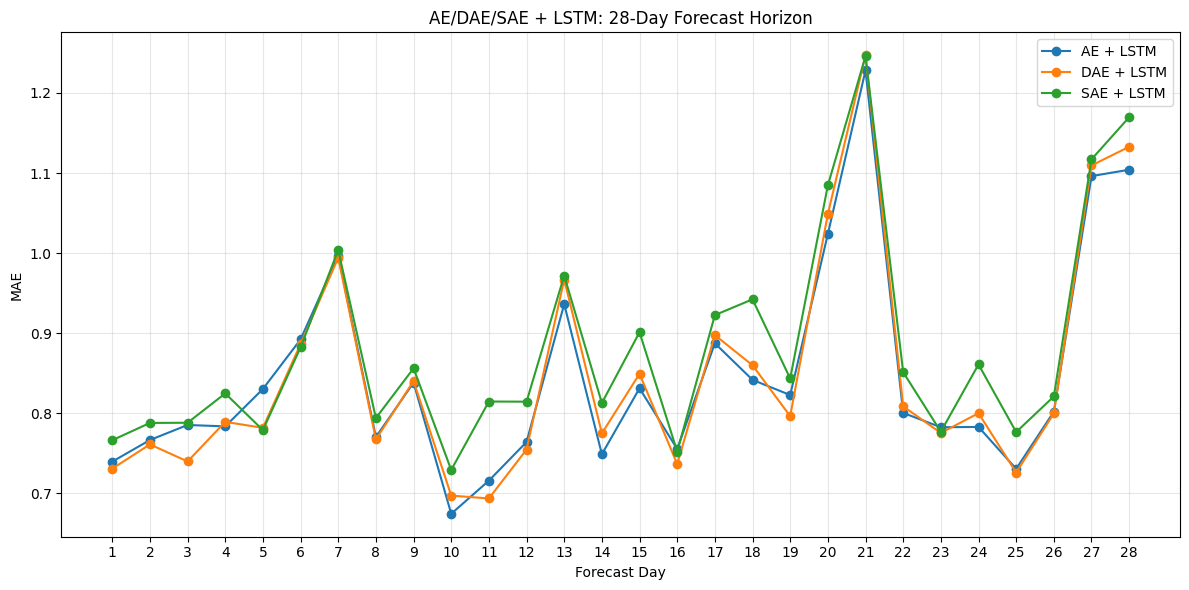

In [ ]:
plt.figure(
    figsize=(12, 6)
)

for model_name in [
    "AE + LSTM",
    "DAE + LSTM",
    "SAE + LSTM"
]:

    temp = step12_horizon_df[
        step12_horizon_df[
            "Model"
        ] == model_name
    ]

    plt.plot(
        temp["Forecast_Day"],
        temp["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Day")
plt.ylabel("MAE")

plt.title(
    "AE/DAE/SAE + LSTM: "
    "28-Day Forecast Horizon"
)

plt.xticks(
    np.arange(1, 29)
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

path = os.path.join(
    FIGURES_DIR,
    "latent_lstm_horizon_comparison.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Plot latent Transformer horizon performance

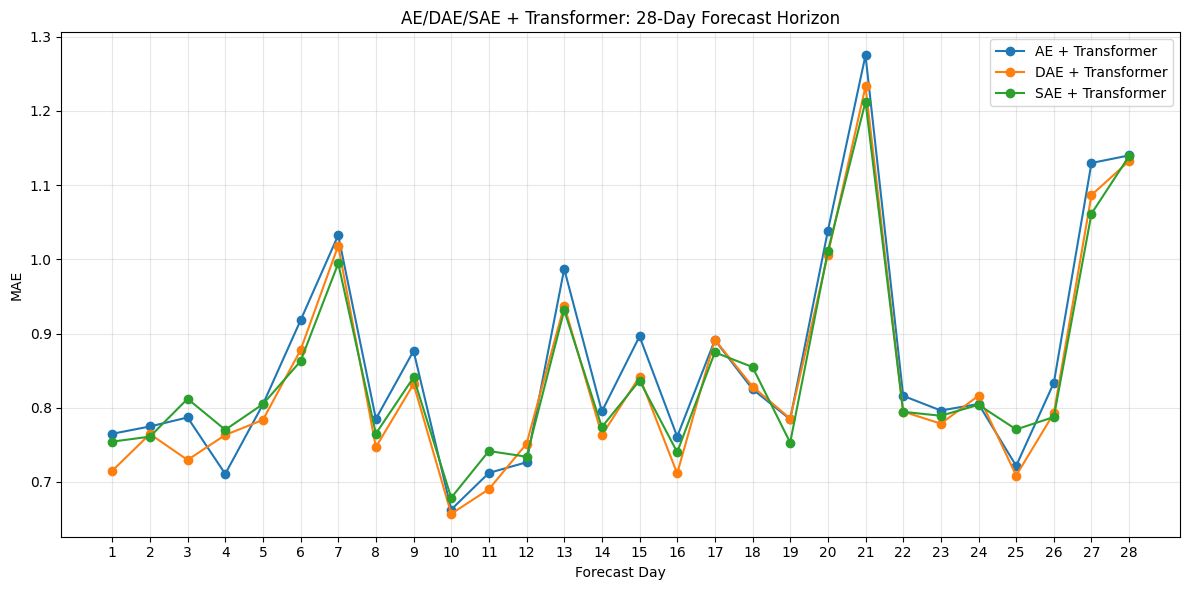

In [ ]:
plt.figure(
    figsize=(12, 6)
)

for model_name in [
    "AE + Transformer",
    "DAE + Transformer",
    "SAE + Transformer"
]:

    temp = step12_horizon_df[
        step12_horizon_df[
            "Model"
        ] == model_name
    ]

    plt.plot(
        temp["Forecast_Day"],
        temp["MAE"],
        marker="o",
        label=model_name
    )

plt.xlabel("Forecast Day")
plt.ylabel("MAE")

plt.title(
    "AE/DAE/SAE + Transformer: "
    "28-Day Forecast Horizon"
)

plt.xticks(
    np.arange(1, 29)
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

path = os.path.join(
    FIGURES_DIR,
    "latent_transformer_horizon_comparison.png"
)

plt.savefig(
    path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Add Step 12 models to complete experiment table

In [ ]:
STEP11_PATH = os.path.join(
    METRICS_DIR,
    "models_with_transformer_comparison.csv"
)

if os.path.exists(
    STEP11_PATH
):

    previous_models = pd.read_csv(
        STEP11_PATH
    )

else:

    previous_models = pd.DataFrame(
        columns=[
            "Model",
            "MAE",
            "RMSE",
            "WAPE",
            "sMAPE"
        ]
    )

step12_model_names = (
    latent_temporal_results[
        "Model"
    ].tolist()
)

previous_models = previous_models[
    ~previous_models[
        "Model"
    ].isin(
        step12_model_names
    )
].copy()

complete_model_comparison = pd.concat(
    [
        previous_models,
        latent_temporal_results
    ],
    ignore_index=True
)

display(
    complete_model_comparison.round(4)
)

,Model,MAE,RMSE,WAPE,sMAPE
0,Seasonal Naive,1.2555,2.8744,105.8198,86.5290
1,MLP,0.9003,1.8435,75.8873,151.5955
2,LightGBM,0.8469,1.8054,71.3810,102.4982
3,AE + MLP,1.0662,1.8089,89.8639,136.1644
4,DAE + MLP,1.1905,2.8978,100.3419,128.1398
5,SAE + MLP,0.9248,1.9480,77.9485,125.4724
6,LSTM,0.8332,1.7894,70.2268,127.8854
7,Transformer,0.8384,1.7694,70.6655,133.3020
8,AE + LSTM,0.8476,1.7896,71.4440,114.0228
9,DAE + LSTM,0.8488,1.7909,71.5465,125.3335


Save complete model comparison

In [ ]:
COMPLETE_COMPARISON_PATH = os.path.join(
    METRICS_DIR,
    "complete_model_comparison.csv"
)

complete_model_comparison.to_csv(
    COMPLETE_COMPARISON_PATH,
    index=False
)

print(
    "Saved:",
    COMPLETE_COMPARISON_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/results/metrics/complete_model_comparison.csv


Plot Step 12 model MAE

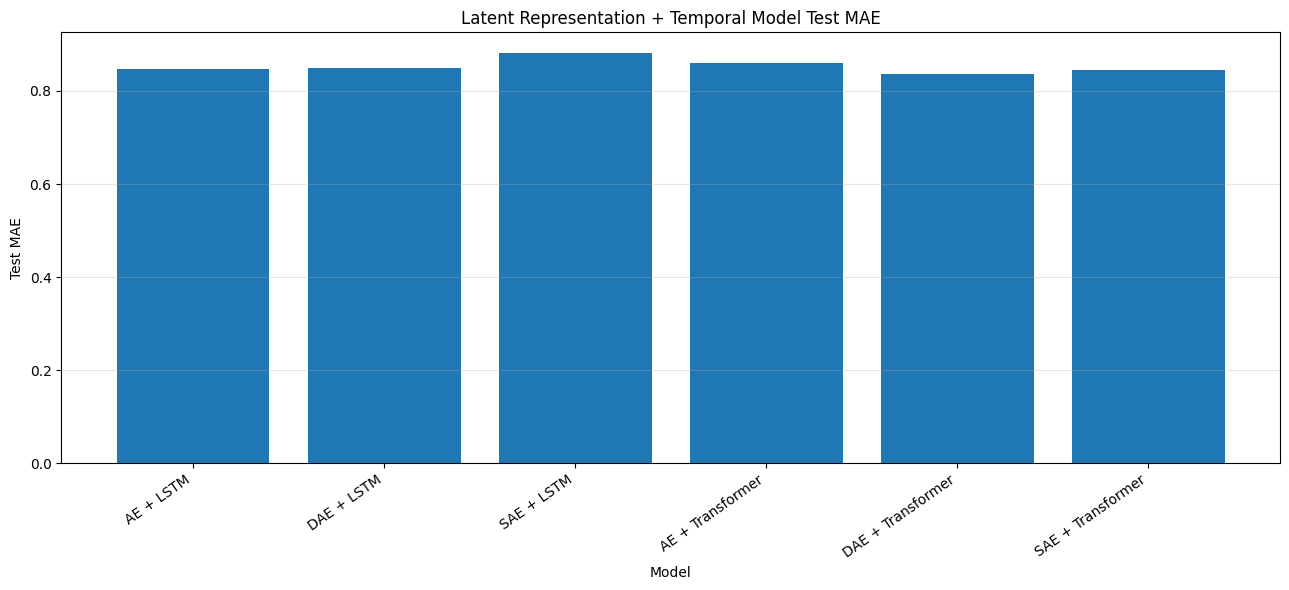

In [ ]:
plt.figure(
    figsize=(13, 6)
)

plt.bar(
    latent_temporal_results[
        "Model"
    ],
    latent_temporal_results[
        "MAE"
    ]
)

plt.xlabel("Model")
plt.ylabel("Test MAE")

plt.title(
    "Latent Representation + Temporal Model "
    "Test MAE"
)

plt.xticks(
    rotation=35,
    ha="right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

STEP12_COMPARISON_FIG = os.path.join(
    FIGURES_DIR,
    "step12_latent_temporal_model_comparison.png"
)

plt.savefig(
    STEP12_COMPARISON_FIG,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Save Step 12 configuration

In [ ]:
step12_config = {

    "sequence_length":
        SEQUENCE_LENGTH,

    "original_features":
        len(FEATURES),

    "latent_dimension":
        LATENT_DIM,

    "forecast_horizon":
        HORIZON,

    "representations": [
        "AE",
        "DAE",
        "SAE"
    ],

    "temporal_models": [
        "LSTM",
        "Transformer"
    ],

    "latent_input_shape": [
        SEQUENCE_LENGTH,
        LATENT_DIM
    ],

    "experiments": [
        "AE + LSTM",
        "DAE + LSTM",
        "SAE + LSTM",
        "AE + Transformer",
        "DAE + Transformer",
        "SAE + Transformer"
    ],

    "metrics": [
        "MAE",
        "RMSE",
        "WAPE",
        "sMAPE"
    ]
}

STEP12_CONFIG_PATH = os.path.join(
    LATENT_TEMPORAL_MODEL_DIR,
    "step12_config.json"
)

with open(
    STEP12_CONFIG_PATH,
    "w"
) as f:

    json.dump(
        step12_config,
        f,
        indent=4
    )

print(
    "Saved:",
    STEP12_CONFIG_PATH
)

Saved: /content/drive/MyDrive/GC210_Retail_Forecasting/models/latent_temporal/step12_config.json


Final verification

In [ ]:
print("=" * 85)
print("STEP 12 - LATENT TEMPORAL MODELING FINAL VERIFICATION")
print("=" * 85)

print("\n1. REPRESENTATION PIPELINE")
print("-" * 50)

print(
    "41 DAILY FEATURES"
)

print(
    "       ↓"
)

print(
    "AE / DAE / SAE"
)

print(
    "       ↓"
)

print(
    f"{LATENT_DIM}-D LATENT VECTOR PER DAY"
)

print(
    "       ↓"
)

print(
    f"{SEQUENCE_LENGTH}-DAY LATENT SEQUENCE"
)

print(
    "       ↓"
)

print(
    "LSTM / TRANSFORMER"
)

print(
    "       ↓"
)

print(
    f"{HORIZON}-DAY FORECAST"
)


print("\n2. INPUT SHAPES")
print("-" * 50)

print(
    "AE Train :",
    X_train_ae.shape
)

print(
    "DAE Train:",
    X_train_dae.shape
)

print(
    "SAE Train:",
    X_train_sae.shape
)

print(
    "AE Test  :",
    X_test_ae.shape
)

print(
    "DAE Test :",
    X_test_dae.shape
)

print(
    "SAE Test :",
    X_test_sae.shape
)


print("\n3. TEST METRICS")
print("-" * 50)

print(
    latent_temporal_results
    .round(4)
    .to_string(index=False)
)


print("\n4. OUTPUT FILES")
print("-" * 50)

files_to_check = {

    "AE train sequence":
        os.path.join(
            LATENT_SEQUENCE_DIR,
            "ae_train.npz"
        ),

    "DAE train sequence":
        os.path.join(
            LATENT_SEQUENCE_DIR,
            "dae_train.npz"
        ),

    "SAE train sequence":
        os.path.join(
            LATENT_SEQUENCE_DIR,
            "sae_train.npz"
        ),

    "Step 12 metrics":
        STEP12_METRICS_PATH,

    "Step 12 predictions":
        STEP12_PREDICTIONS_PATH,

    "Horizon metrics":
        STEP12_HORIZON_PATH,

    "Complete comparison":
        COMPLETE_COMPARISON_PATH,

    "Step 12 config":
        STEP12_CONFIG_PATH,

    "AE-LSTM model":
        os.path.join(
            LATENT_TEMPORAL_MODEL_DIR,
            "ae_lstm.keras"
        ),

    "DAE-LSTM model":
        os.path.join(
            LATENT_TEMPORAL_MODEL_DIR,
            "dae_lstm.keras"
        ),

    "SAE-LSTM model":
        os.path.join(
            LATENT_TEMPORAL_MODEL_DIR,
            "sae_lstm.keras"
        ),

    "AE-Transformer":
        os.path.join(
            LATENT_TEMPORAL_MODEL_DIR,
            "ae_transformer.keras"
        ),

    "DAE-Transformer":
        os.path.join(
            LATENT_TEMPORAL_MODEL_DIR,
            "dae_transformer.keras"
        ),

    "SAE-Transformer":
        os.path.join(
            LATENT_TEMPORAL_MODEL_DIR,
            "sae_transformer.keras"
        )
}

all_saved = True

for name, path in (
    files_to_check.items()
):

    exists = os.path.exists(
        path
    )

    print(
        f"{name:28s}:",
        "FOUND"
        if exists
        else "MISSING"
    )

    if not exists:
        all_saved = False


print("\n" + "=" * 85)

if all_saved:

    print(
        "STEP 12 COMPLETED SUCCESSFULLY"
    )

    print(
        "41 FEATURES -> AE/DAE/SAE -> "
        "28 x 8 LATENT SEQUENCES -> "
        "LSTM/TRANSFORMER -> "
        "28-DAY FORECAST"
    )

else:

    print(
        "STEP 12 INCOMPLETE - "
        "CHECK MISSING FILES ABOVE"
    )

print("=" * 85)

STEP 12 - LATENT TEMPORAL MODELING FINAL VERIFICATION

1. REPRESENTATION PIPELINE
--------------------------------------------------
41 DAILY FEATURES
       ↓
AE / DAE / SAE
       ↓
8-D LATENT VECTOR PER DAY
       ↓
28-DAY LATENT SEQUENCE
       ↓
LSTM / TRANSFORMER
       ↓
28-DAY FORECAST

2. INPUT SHAPES
--------------------------------------------------
AE Train : (79200, 28, 8)
DAE Train: (79200, 28, 8)
SAE Train: (79200, 28, 8)
AE Test  : (300, 28, 8)
DAE Test : (300, 28, 8)
SAE Test : (300, 28, 8)

3. TEST METRICS
--------------------------------------------------
            Model    MAE   RMSE    WAPE    sMAPE
        AE + LSTM 0.8476 1.7896 71.4440 114.0228
       DAE + LSTM 0.8488 1.7909 71.5465 125.3335
       SAE + LSTM 0.8819 1.8245 74.3301 132.4461
 AE + Transformer 0.8590 1.8795 72.4039 126.6875
DAE + Transformer 0.8372 1.7858 70.5612 119.5099
SAE + Transformer 0.8449 1.7772 71.2111 115.7377

4. OUTPUT FILES
--------------------------------------------------
AE train